# LeNet：CIFAR-10 图像分类

**学习目标：**准备可复现的数据集、查看张量形状、训练分类器、用验证集挑选检查点，
并在独立的测试集上评估。本版本的所有类别名与图表均为中文。

请从上到下依次运行单元。第一次下载数据集/模型需要联网。
纯 CPU 也能运行；启动内核前设置 `COURSE_SMOKE=1` 可以做一次短流程检查。
冒烟测试的分数用来说明流程是否跑通，不代表模型质量。


In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('torch').split("+")[0] == '2.14.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('torch' + "：", version('torch'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数
```

In [2]:
from pathlib import Path
import os
import sys

# 不依赖当前工作目录，向上找到中文课程根目录。
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "CHINESE_COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("请在项目根目录（中文课程）中启动 Jupyter。")
ENGLISH = COURSE / "english"
# 中文专用模块在仓库根 common/，与英文课程共享的数据与检测模块在 english/common。
sys.path.insert(0, str(ENGLISH / "common"))
sys.path.insert(0, str(COURSE / "common"))
# 模型权重缓存与英文课程共用一份，避免同一份权重重复下载。
os.environ.setdefault("HF_HOME", str(ENGLISH / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(ENGLISH / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**预期输出：**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

In [3]:
EXPERIMENT = "lenet-cifar10"

import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
from course_zh import setup_chinese_fonts
setup_chinese_fonts(plt)
print("图表中文字体：", setup_chinese_fonts(plt))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
DATA = COURSE / "01-image-classification" / "data"
OUTPUT = COURSE / "01-image-classification" / "outputs" / EXPERIMENT
DATA.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
EPOCHS = 1 if SMOKE else 3
BATCH_SIZE = 32 if SMOKE else 64
print(f"计算设备：{DEVICE}；实验：{EXPERIMENT}；冒烟测试：{SMOKE}")

图表中文字体： PingFang SC
计算设备：mps；实验：lenet-cifar10；冒烟测试：False


**预期输出：**

```text
图表中文字体： PingFang SC
计算设备：mps；实验：lenet-cifar10；冒烟测试：False
```

## 1. 准备训练集、验证集和测试集

官方测试集在最终评估之前保持不动，验证数据只从训练集中划分出来，划分由固定随机种子决定。
课堂运行只取一个子集以控制耗时；想做更充分的实验可以放大这些上限。


In [4]:
CLASS_NAMES = ["飞机", "汽车", "鸟", "猫", "鹿", "狗", "青蛙", "马", "船", "卡车"]
CHANNELS, IMAGE_SIZE = 3, 32
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5,)*3, (0.5,)*3)])
from vision_data import load_cifar10
full_train = load_cifar10(DATA / "cifar10", train=True, transform=transform)
test_set = load_cifar10(DATA / "cifar10", train=False, transform=transform)

val_size = len(full_train) // 10
train_set, val_set = random_split(full_train, [len(full_train) - val_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))
train_set = Subset(train_set, range(min(len(train_set), 64 if SMOKE else 4000)))
val_set = Subset(val_set, range(min(len(val_set), 32 if SMOKE else 1000)))
test_set = Subset(test_set, range(min(len(test_set), 32 if SMOKE else 1000)))

批次形状： (64, 3, 32, 32) 标签形状： (64,)
数据集划分规模： 4000 1000 1000


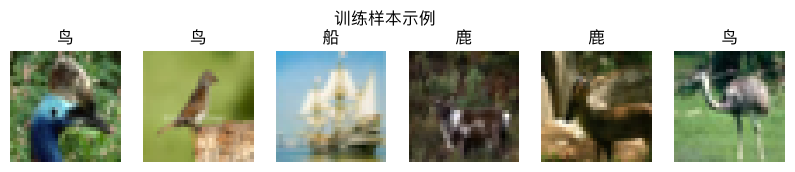

In [5]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=0)
images, labels = next(iter(train_loader))
print("批次形状：", tuple(images.shape), "标签形状：", tuple(labels.shape))
print("数据集划分规模：", len(train_set), len(val_set), len(test_set))
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for axis, image, label in zip(axes, images, labels):
    view = image[0] if CHANNELS == 1 else image.permute(1, 2, 0)
    view = (view - view.min()) / (view.max() - view.min() + 1e-8)
    axis.imshow(view, cmap="gray" if CHANNELS == 1 else None)
    axis.set_title(CLASS_NAMES[int(label)])
    axis.axis("off")
fig.suptitle("训练样本示例")
plt.show()

**预期输出：**

```text
批次形状： (64, 3, 32, 32) 标签形状： (64,)
数据集划分规模： 4000 1000 1000
```

**预期输出（图片）：**

![准备训练集、验证集和测试集](../assets/02-lenet-cifar10-1.png)

*准备训练集、验证集和测试集*

## 2. 定义模型

卷积用共享权重学习局部特征，池化缩小空间尺寸，最后的线性层为每个类别输出一个 logit。
交叉熵损失接收的是 logit，因此 softmax 只在展示预测概率时使用。


In [6]:
class LeNet(nn.Module):
    def __init__(self, in_channels=1, image_size=28, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 6, kernel_size=5, padding=2), nn.ReLU(),
            nn.AvgPool2d(2), nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),
            nn.AvgPool2d(2), nn.Flatten())
        with torch.no_grad():
            width = self.features(torch.zeros(1, in_channels, image_size, image_size)).shape[1]
        self.classifier = nn.Sequential(nn.Linear(width, 120), nn.ReLU(),
                                        nn.Linear(120, 84), nn.ReLU(),
                                        nn.Linear(84, num_classes))

    def forward(self, images):
        return self.classifier(self.features(images))

model = LeNet(CHANNELS, IMAGE_SIZE, len(CLASS_NAMES)).to(DEVICE)
print("模型输出形状：", tuple(model(torch.zeros(2, CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape))

模型输出形状： (2, 10)


**预期输出：**

```text
模型输出形状： (2, 10)
```

## 3. 训练并挑选检查点

训练时开启梯度并更新参数；评估时关闭梯度，并让 dropout/批归一化切换到评估行为。
保存验证准确率最高的检查点，绝不能用测试准确率来挑选。


In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=0.001)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

history, best_accuracy = [], -1.0
checkpoint = OUTPUT / "best_model.pt"
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint)
    print(f"第 {epoch + 1}/{EPOCHS} 轮 | 训练损失 {train_loss:.4f} | "
          f"验证损失 {val_loss:.4f} | 验证准确率 {val_accuracy:.3f}")

第 1/3 轮 | 训练损失 2.1688 | 验证损失 2.0284 | 验证准确率 0.269


第 2/3 轮 | 训练损失 1.9187 | 验证损失 1.8857 | 验证准确率 0.311


第 3/3 轮 | 训练损失 1.7591 | 验证损失 1.7886 | 验证准确率 0.335


**预期输出：**

```text
第 1/3 轮 | 训练损失 2.1688 | 验证损失 2.0284 | 验证准确率 0.269
第 2/3 轮 | 训练损失 1.9187 | 验证损失 1.8857 | 验证准确率 0.311
第 3/3 轮 | 训练损失 1.7591 | 验证损失 1.7886 | 验证准确率 0.335
```

## 4. 评估已保存的检查点


留出测试集准确率：0.371


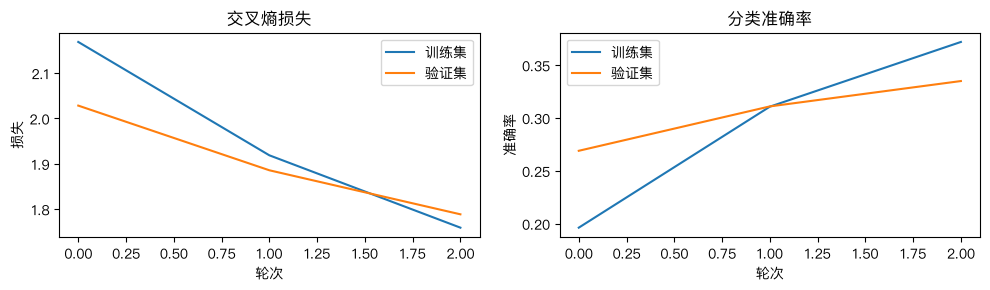

In [8]:
import json
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
test_loss, test_accuracy = run_epoch(test_loader)
print(f"留出测试集准确率：{test_accuracy:.3f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "epochs": EPOCHS, "classes": CLASS_NAMES}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
values = np.asarray(history)
axes[0].plot(values[:, 0], label="训练集")
axes[0].plot(values[:, 1], label="验证集")
axes[0].set(title="交叉熵损失", xlabel="轮次", ylabel="损失")
axes[1].plot(values[:, 2], label="训练集")
axes[1].plot(values[:, 3], label="验证集")
axes[1].set(title="分类准确率", xlabel="轮次", ylabel="准确率")
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "training_curves.png")
plt.show()

**预期输出：**

```text
留出测试集准确率：0.371
```

**预期输出（图片）：**

![评估已保存的检查点](../assets/02-lenet-cifar10-2.png)

*评估已保存的检查点*

## 5. 观察错误样本并对单张图片做预测


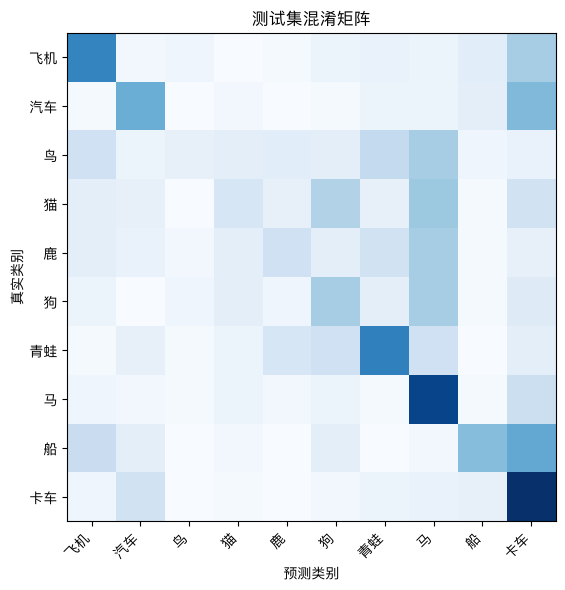

错分样本：真实=猫，预测=汽车
错分样本：真实=船，预测=卡车
错分样本：真实=飞机，预测=船
错分样本：真实=青蛙，预测=鹿
错分样本：真实=汽车，预测=狗
错分样本：真实=青蛙，预测=鹿


预测结果：汽车 | 置信度：0.206 | 真实标签：猫


In [9]:
confusion = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)
mistakes = []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(DEVICE)).argmax(1).cpu()
        for image, true, predicted in zip(images, labels, predictions):
            confusion[int(true), int(predicted)] += 1
            if true != predicted and len(mistakes) < 6:
                mistakes.append((image, int(true), int(predicted)))
fig, axis = plt.subplots(figsize=(7, 6))
axis.imshow(confusion, cmap="Blues")
axis.set(xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)),
         xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
         xlabel="预测类别", ylabel="真实类别", title="测试集混淆矩阵")
plt.setp(axis.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(OUTPUT / "confusion_matrix.png")
plt.show()
for _, true, predicted in mistakes:
    print(f"错分样本：真实={CLASS_NAMES[true]}，预测={CLASS_NAMES[predicted]}")

# Single-image inference uses the same preprocessing as evaluation.
image, true_label = test_set[0]
with torch.no_grad():
    probabilities = model(image.unsqueeze(0).to(DEVICE)).softmax(1)[0].cpu()
prediction = int(probabilities.argmax())
print(f"预测结果：{CLASS_NAMES[prediction]} | 置信度：{probabilities[prediction]:.3f} | "
      f"真实标签：{CLASS_NAMES[int(true_label)]}")

**预期输出：**

```text
错分样本：真实=猫，预测=汽车
错分样本：真实=船，预测=卡车
错分样本：真实=飞机，预测=船
错分样本：真实=青蛙，预测=鹿
错分样本：真实=汽车，预测=狗
错分样本：真实=青蛙，预测=鹿
预测结果：汽车 | 置信度：0.206 | 真实标签：猫
```

**预期输出（图片）：**

![观察错误样本并对单张图片做预测](../assets/02-lenet-cifar10-3.png)

*观察错误样本并对单张图片做预测*

## 练习与讨论

1. 运行模型之前，先预测每个张量的形状。
2. 在保持划分不变的前提下比较不同学习率。
3. 解释验证结果和测试结果为什么会不一致。
4. 先观察被分错的样本，再考虑加大模型。
5. 对新图片做预测时，使用与评估完全一致的预处理和类别映射。

模型权重、类别名、随机种子和指标都保存在本实验的输出目录下。
结果会随子集规模、硬件和训练时长而变化。
